# **Predicting ESG Scores with Corporate Performance Metrics**

### **Data Loading and Inspection**

In [106]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [108]:
df=pd.read_csv('/content/drive/My Drive/company_esg_financial_dataset.csv')

In [109]:
df_copy=df.copy()

each row in this dataset tell the story for each year for several companies. We can say this data is not normalized dataset.

In [110]:
df.head()

,CompanyID,CompanyName,Industry,Region,Year,Revenue,ProfitMargin,MarketCap,GrowthRate,ESG_Overall,ESG_Environmental,ESG_Social,ESG_Governance,CarbonEmissions,WaterUsage,EnergyConsumption
0,1,Company_1,Retail,Latin America,2015,459.2,6.0,337.5,NaN,57.0,60.7,33.5,76.8,35577.4,17788.7,71154.7
1,1,Company_1,Retail,Latin America,2016,473.8,4.6,366.6,3.2,56.7,58.9,32.8,78.5,37314.7,18657.4,74629.4
2,1,Company_1,Retail,Latin America,2017,564.9,5.2,313.4,19.2,56.5,57.6,34.0,77.8,45006.4,22503.2,90012.9
3,1,Company_1,Retail,Latin America,2018,558.4,4.3,283.0,-1.1,58.0,62.3,33.4,78.3,42650.1,21325.1,85300.2
4,1,Company_1,Retail,Latin America,2019,554.5,4.9,538.1,-0.7,56.6,63.7,30.0,76.1,41799.4,20899.7,83598.8




1. CompanyID:	Unique identifier for each synthetic company:	Numeric

2. CompanyName:	Synthetic name (e.g., "Company_123"):	Categorical
3. Industry:Industry sector (e.g., Technology, Finance, Energy):	Categorical
4. Region:	Geographic region (e.g., North America, Europe):	Categorical
5. Year:	Reporting year (2015–2025):	Numeric
6. Revenue:	Annual revenue in millions USD:	Numeric
7. ProfitMargin:	Net profit margin as percentage of revenue:	Numeric
8. MarketCap:	Market capitalization in millions USD:	Numeric
9. GrowthRate:	Year-over-year revenue growth rate (%):	Numeric (NaN for 2015)
10. ESG_Overall:	Aggregate ESG sustainability score (0–100):	Numeric
11. ESG_Environmental:	Environmental sustainability score (0–100):	Numeric
12. ESG_Social:	Social responsibility score (0–100):	Numeric
13. ESG_Governance:	Corporate governance quality score (0–100):	Numeric
14. CarbonEmissions:	Annual carbon emissions in tons CO₂:	Numeric
15. WaterUsage:	Annual water usage in cubic meters:	Numeric
16. EnergyConsumption:	Annual energy consumption in megawatt-hours (MWh):	Numeric

In [111]:
df.tail(10)

,CompanyID,CompanyName,Industry,Region,Year,Revenue,ProfitMargin,MarketCap,GrowthRate,ESG_Overall,ESG_Environmental,ESG_Social,ESG_Governance,CarbonEmissions,WaterUsage,EnergyConsumption
10990,1000,Company_1000,Consumer Goods,Latin America,2016,2459.4,14.7,8024.3,3.0,49.0,61.8,42.6,42.5,377376.2,471720.3,1886881.0
10991,1000,Company_1000,Consumer Goods,Latin America,2017,2685.8,16.3,10157.8,9.2,50.3,65.2,46.4,39.1,399264.1,499080.1,1996320.4
10992,1000,Company_1000,Consumer Goods,Latin America,2018,2778.2,16.9,10003.6,3.4,48.3,64.9,42.2,37.8,414154.8,517693.5,2070774.1
10993,1000,Company_1000,Consumer Goods,Latin America,2019,2798.3,16.8,6684.5,0.7,48.9,66.8,41.1,38.9,409725.5,512156.9,2048627.7
10994,1000,Company_1000,Consumer Goods,Latin America,2020,3405.5,19.5,8599.9,21.7,50.4,68.0,42.6,40.5,492885.5,616106.9,2464427.6
10995,1000,Company_1000,Consumer Goods,Latin America,2021,3419.2,21.7,14416.7,0.4,52.2,67.2,46.3,43.1,498875.8,623594.7,2494378.8
10996,1000,Company_1000,Consumer Goods,Latin America,2022,3518.8,21.4,8078.9,2.9,51.9,68.7,44.7,42.3,506013.7,632517.1,2530068.4
10997,1000,Company_1000,Consumer Goods,Latin America,2023,3417.1,17.1,13263.4,-2.9,52.9,72.4,43.1,43.2,473561.5,591951.9,2367807.7
10998,1000,Company_1000,Consumer Goods,Latin America,2024,3183.2,15.7,6960.1,-6.8,52.0,72.4,40.5,42.9,441310.9,551638.6,2206554.3
10999,1000,Company_1000,Consumer Goods,Latin America,2025,3173.5,17.5,5666.1,-0.3,51.8,74.5,39.7,41.4,430741.6,538427.0,2153707.9


In [112]:
df.shape

(11000, 16)

In [113]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11000 entries, 0 to 10999
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CompanyID          11000 non-null  int64  
 1   CompanyName        11000 non-null  object 
 2   Industry           11000 non-null  object 
 3   Region             11000 non-null  object 
 4   Year               11000 non-null  int64  
 5   Revenue            11000 non-null  float64
 6   ProfitMargin       11000 non-null  float64
 7   MarketCap          11000 non-null  float64
 8   GrowthRate         10000 non-null  float64
 9   ESG_Overall        11000 non-null  float64
 10  ESG_Environmental  11000 non-null  float64
 11  ESG_Social         11000 non-null  float64
 12  ESG_Governance     11000 non-null  float64
 13  CarbonEmissions    11000 non-null  float64
 14  WaterUsage         11000 non-null  float64
 15  EnergyConsumption  11000 non-null  float64
dtypes: float64(11), int64(

In [114]:
df.columns=df.columns.str.lower().str.strip().str.replace(r'\s+','_',regex=True)

In [115]:
df=df.apply(lambda x: x.astype(str).str.strip().str.lower().str.replace(r'\s+', '_', regex=True)) #to clean values in the dataset

In [116]:
df['year']=df['year'].astype(int)

In [117]:
columns_to_convert = ['revenue','profitmargin','marketcap','growthrate','esg_overall','esg_environmental','esg_social','esg_governance','carbonemissions','waterusage','energyconsumption']
for col in columns_to_convert:
    df[col] = pd.to_numeric(df[col], errors='coerce')

In [118]:
df.isnull().sum() #handling this null will depend on the ML algo we will use.

,0
companyid,0
companyname,0
industry,0
region,0
year,0
revenue,0
profitmargin,0
marketcap,0
growthrate,1000
esg_overall,0


In [119]:
#the ML algorithm we will use for this is Regression, so it is better to drop as supervised model cannot handle any missing rows
df=df.dropna()

In [120]:
df.duplicated(subset=['companyid']).sum() #no duplicates, so companyid is not a primary key

np.int64(9000)

In [121]:
df.columns

Index(['companyid', 'companyname', 'industry', 'region', 'year', 'revenue',
       'profitmargin', 'marketcap', 'growthrate', 'esg_overall',
       'esg_environmental', 'esg_social', 'esg_governance', 'carbonemissions',
       'waterusage', 'energyconsumption'],
      dtype='object')

In [122]:
df['industry'].unique()

array(['retail', 'transportation', 'technology', 'finance', 'healthcare',
       'energy', 'consumer_goods', 'utilities', 'manufacturing'],
      dtype=object)

In [123]:
df['region'].unique()

array(['latin_america', 'asia', 'africa', 'middle_east', 'oceania',
       'europe', 'north_america'], dtype=object)

In [124]:
df.describe()

,year,revenue,profitmargin,marketcap,growthrate,esg_overall,esg_environmental,esg_social,esg_governance,carbonemissions,waterusage,energyconsumption
count,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,1.000000e+04,1.000000e+04,1.000000e+04
mean,2020.500000,4807.351600,10.90259,13809.568800,4.830370,54.932610,56.868070,55.913460,52.015760,1.299388e+06,5.719516e+05,1.190684e+07
std,2.872425,10282.955742,8.92430,41034.936707,9.424787,15.870373,26.702725,23.363477,25.323476,5.240311e+06,1.617406e+06,5.268540e+07
min,2016.000000,35.900000,-20.00000,1.800000,-36.000000,6.300000,0.000000,0.000000,0.000000,2.042200e+03,1.021100e+03,5.105500e+03
25%,2018.000000,953.725000,5.20000,1116.050000,-1.325000,44.400000,35.200000,37.900000,30.900000,1.258106e+05,6.654732e+04,3.140719e+05
50%,2020.500000,1951.800000,10.60000,3190.300000,4.900000,55.000000,56.050000,55.400000,52.400000,2.962395e+05,2.074155e+05,1.237721e+06
75%,2023.000000,4457.200000,16.40000,10359.425000,11.000000,65.900000,79.500000,74.000000,73.300000,7.508462e+05,5.329517e+05,5.660458e+06
max,2025.000000,180810.400000,50.00000,865271.700000,38.000000,98.800000,100.000000,100.000000,100.000000,1.741047e+08,5.223142e+07,1.741047e+09


In [125]:
pd.options.display.float_format = '{:.2f}'.format

Most of the time, next step is feature engineering and scaling, but that will happen when you have problem statement at your hand, get that and we will proceed further.

## **Description of Columns**

### **Problem Statement**

Can a company's financial performance and operational indicators predict its ESG score?

Target:

**ESG_Overall**

Features:

1. Revenue
2. ProfitMargin
3. MarketCap
4. GrowthRate
5. Industry
6. Region
7. Year
7. CarbonEmissions
8. WaterUsage
9. EnergyConsumption

Model:

**Regression**

Possible algorithms

1. Linear Regression (baseline)
2. Random Forest
3. XGBoost
4. LightGBM
5. CatBoost

Evaluation:

1. RMSE
2. MAE
3. R²

Extra skills to showcase

1. Feature importance
2. SHAP values
3. Partial Dependence Plots
4. Hyperparameter tuning
5. Cross Validation

## **EDA**

#### Univariate

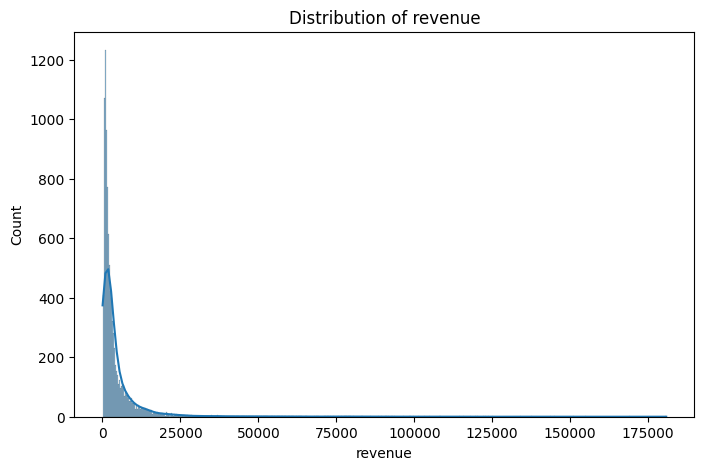

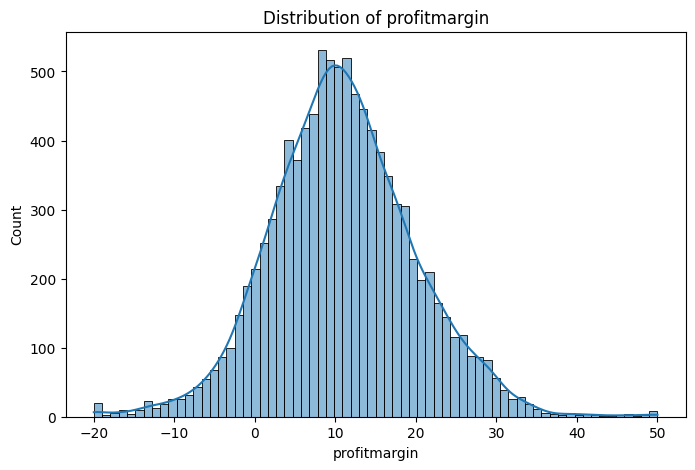

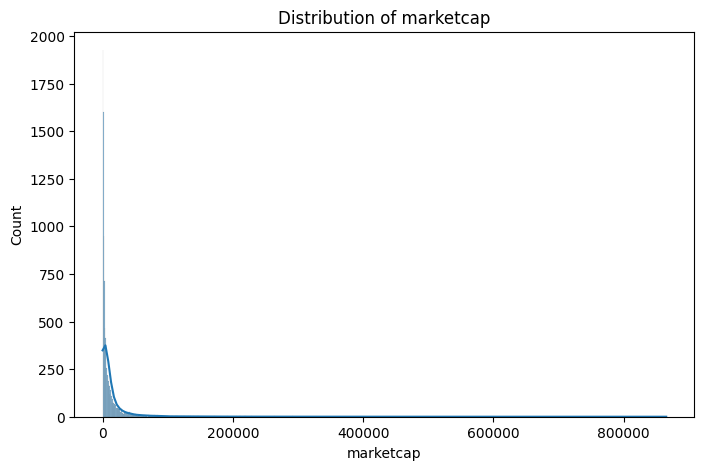

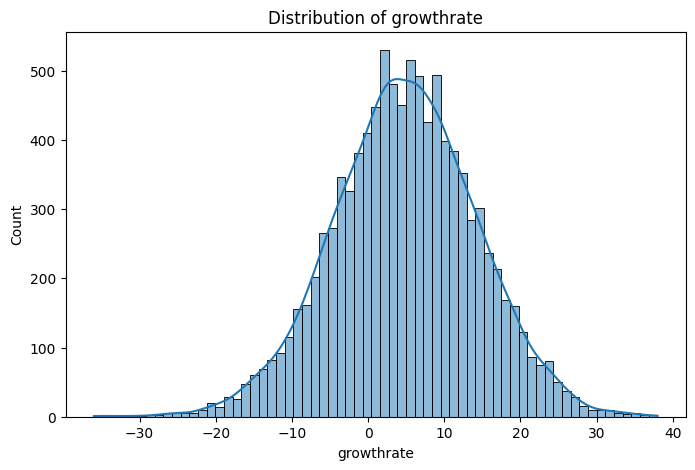

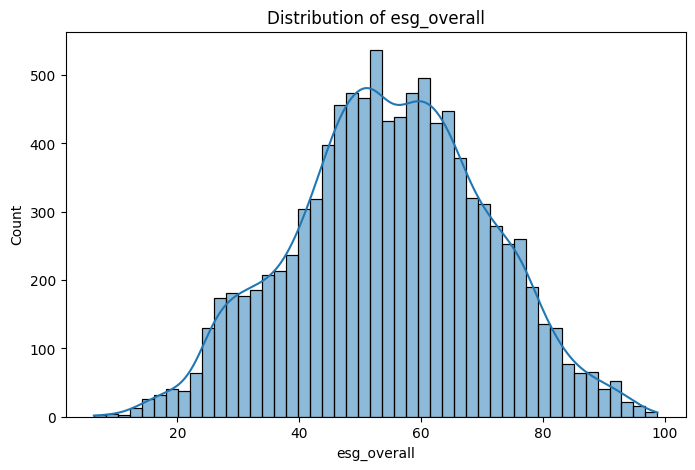

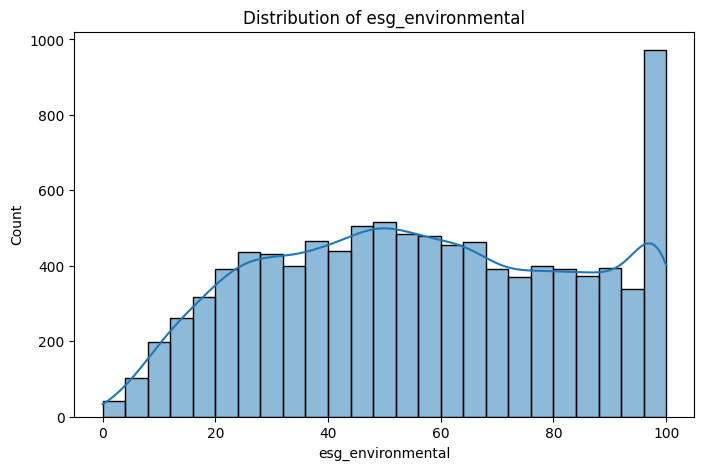

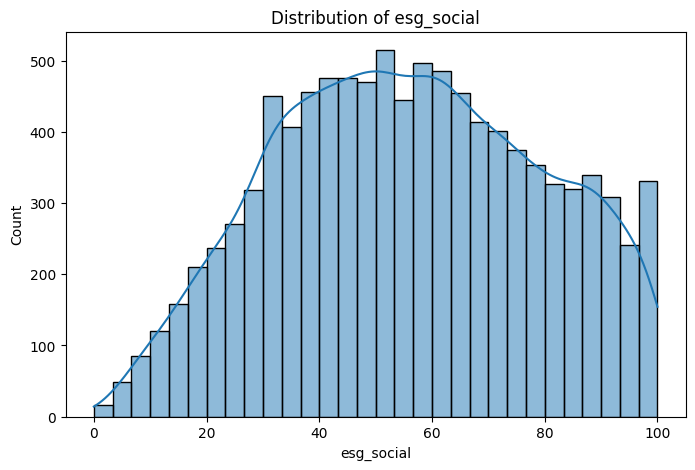

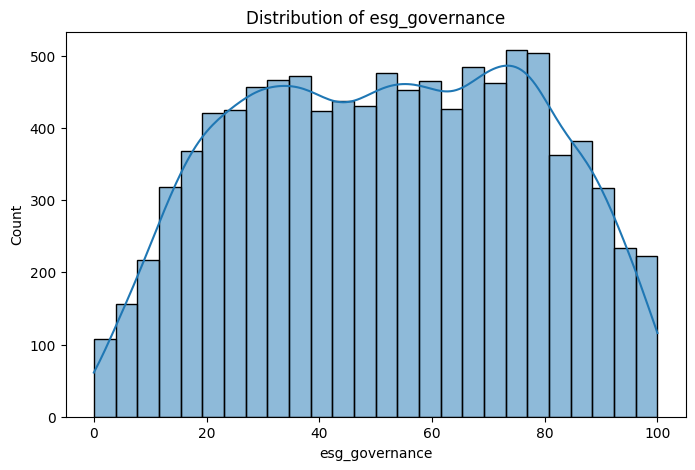

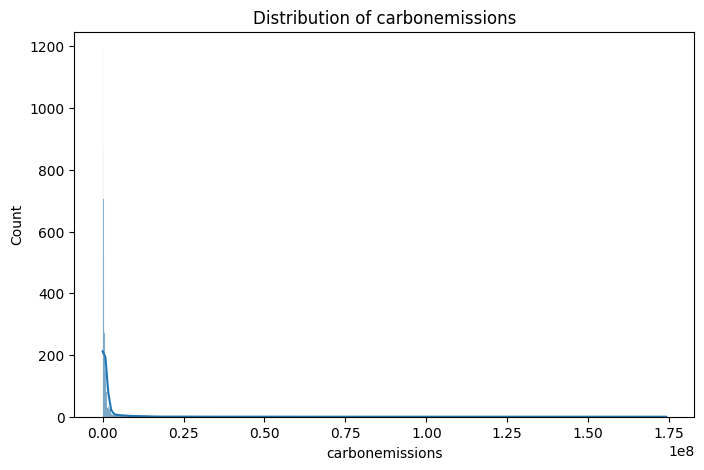

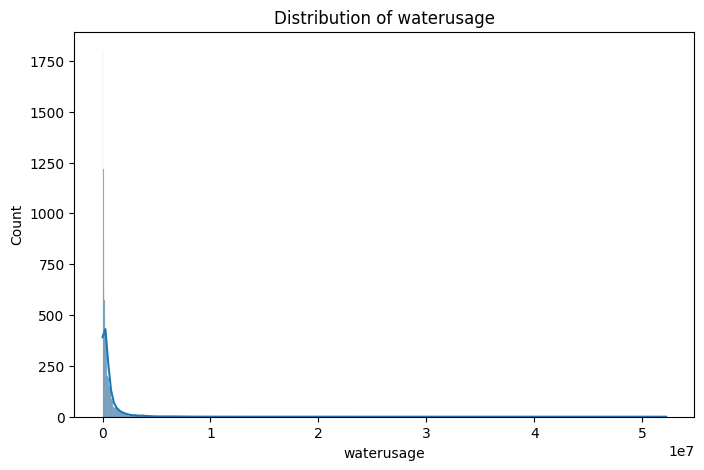

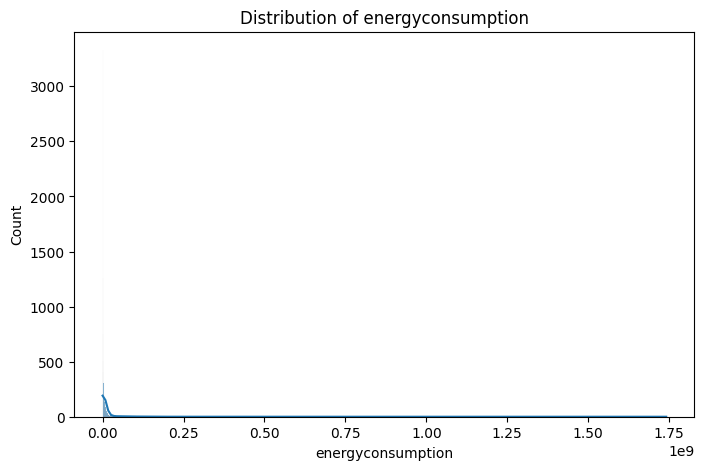

In [126]:
df_numeric = df[['revenue','profitmargin','marketcap','growthrate',
                 'esg_overall','esg_environmental','esg_social','esg_governance',
                 'carbonemissions','waterusage','energyconsumption']]
# Iterate and plot
for column in df_numeric.columns:
    plt.figure(figsize=(8, 5))
    sns.histplot(data=df_numeric, x=column, kde=True) # Added kde=True for density curve
    plt.title(f'Distribution of {column}')
    plt.show()


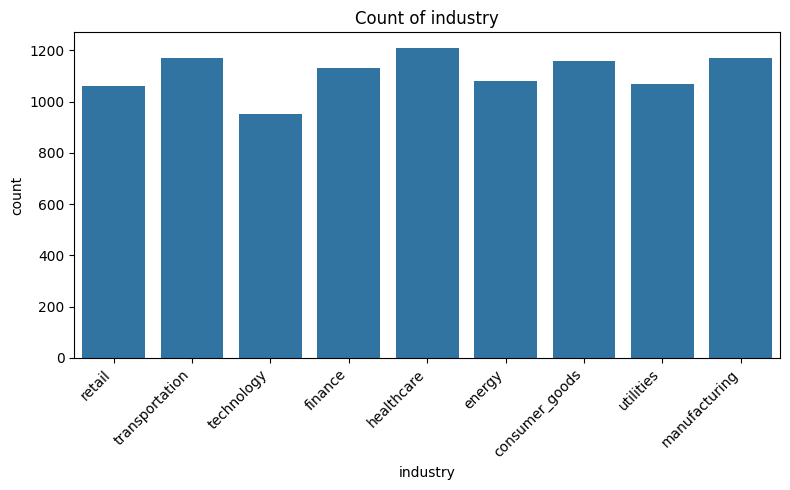

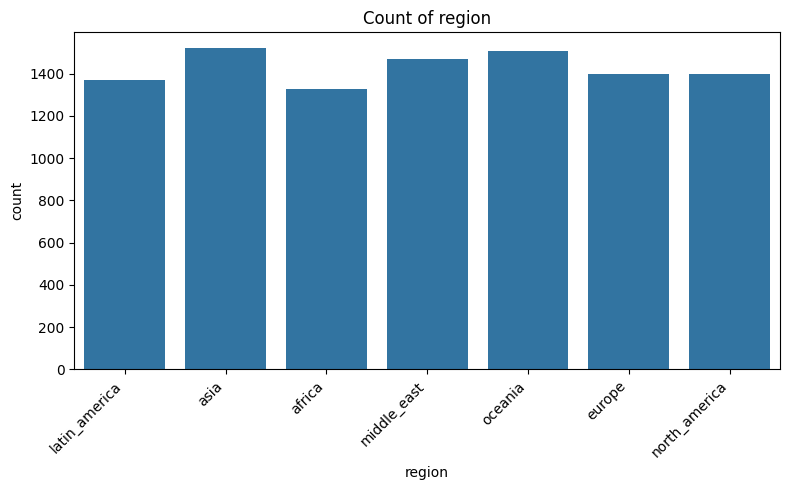

In [127]:
df_categorical=df[['industry','region']]
for cols in df_categorical:
  plt.figure(figsize=(8,5))
  sns.countplot(data=df_categorical,x=cols)
  plt.title(f'Count of {cols}')
  plt.xticks(rotation=45, ha="right")
  plt.tight_layout()
  plt.show()

#### Bi-Variate

In [128]:
industry_esg=df.groupby('industry').agg({'esg_overall':'mean'}).rename({'esg_overall':'avg_esg_score'}).sort_values(by='esg_overall',ascending=False).reset_index()
industry_esg

,industry,esg_overall
0,finance,64.86
1,technology,63.59
2,healthcare,57.57
3,retail,56.03
4,consumer_goods,55.18
5,utilities,51.93
6,manufacturing,50.79
7,energy,49.36
8,transportation,46.38


In [129]:
region_esg=df.groupby('region').agg({'esg_overall':'mean'}).rename({'esg_overall':'avg_esg_score'}).sort_values(by='esg_overall',ascending=False).reset_index()
region_esg

,region,esg_overall
0,europe,68.15
1,oceania,62.73
2,north_america,61.53
3,asia,52.24
4,latin_america,50.86
5,africa,44.85
6,middle_east,43.75


In [130]:
year_esg=df.groupby('year').agg({'esg_overall':'mean'}).rename({'esg_overall':'avg_esg_score'}).sort_values(by='esg_overall',ascending=False).reset_index()
year_esg

,year,esg_overall
0,2025,57.83
1,2024,57.18
2,2023,56.59
3,2022,55.92
4,2021,55.24
5,2020,54.59
6,2019,53.91
7,2018,53.35
8,2017,52.68
9,2016,52.04


<Axes: xlabel='energyconsumption', ylabel='esg_overall'>

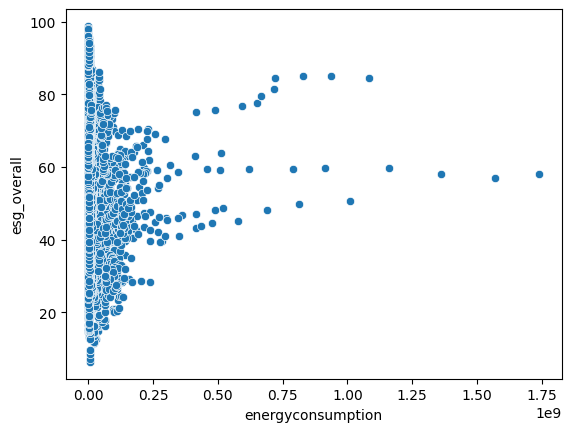

In [132]:
sns.scatterplot(x='energyconsumption',y='esg_overall',data=df)

<Axes: xlabel='profitmargin', ylabel='esg_overall'>

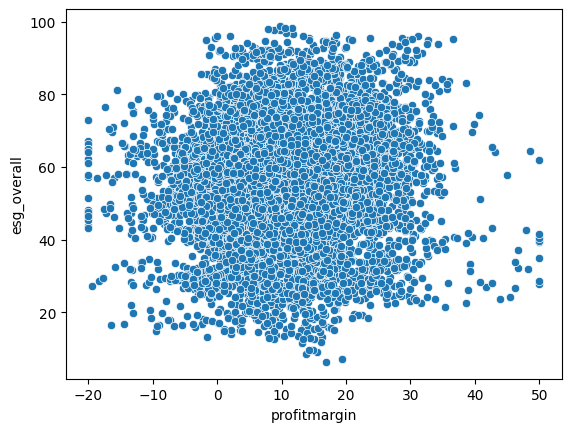

In [133]:
sns.scatterplot(x='profitmargin',y='esg_overall',data=df)

<Axes: xlabel='carbonemissions', ylabel='esg_overall'>

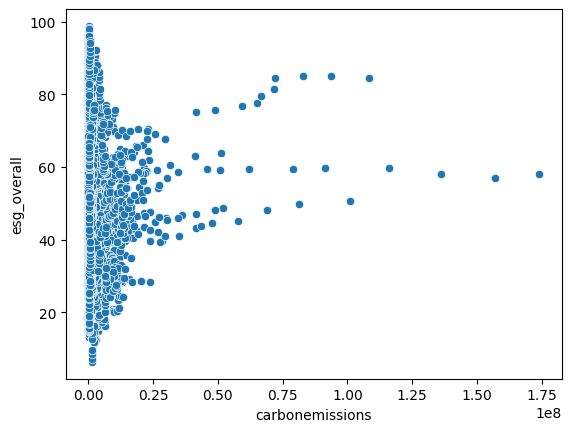

In [134]:
sns.scatterplot(x='carbonemissions',y='esg_overall',data=df)

#### Multivariate

<Axes: >

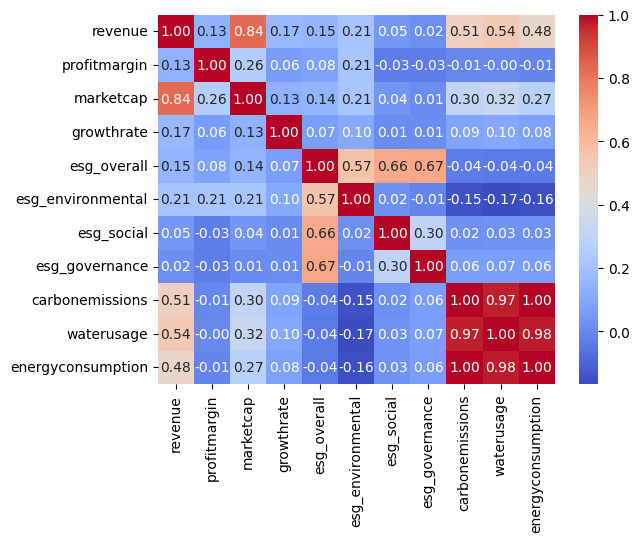

In [135]:
correlation_matrix = df_numeric.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')

In [136]:
df.columns

Index(['companyid', 'companyname', 'industry', 'region', 'year', 'revenue',
       'profitmargin', 'marketcap', 'growthrate', 'esg_overall',
       'esg_environmental', 'esg_social', 'esg_governance', 'carbonemissions',
       'waterusage', 'energyconsumption'],
      dtype='object')

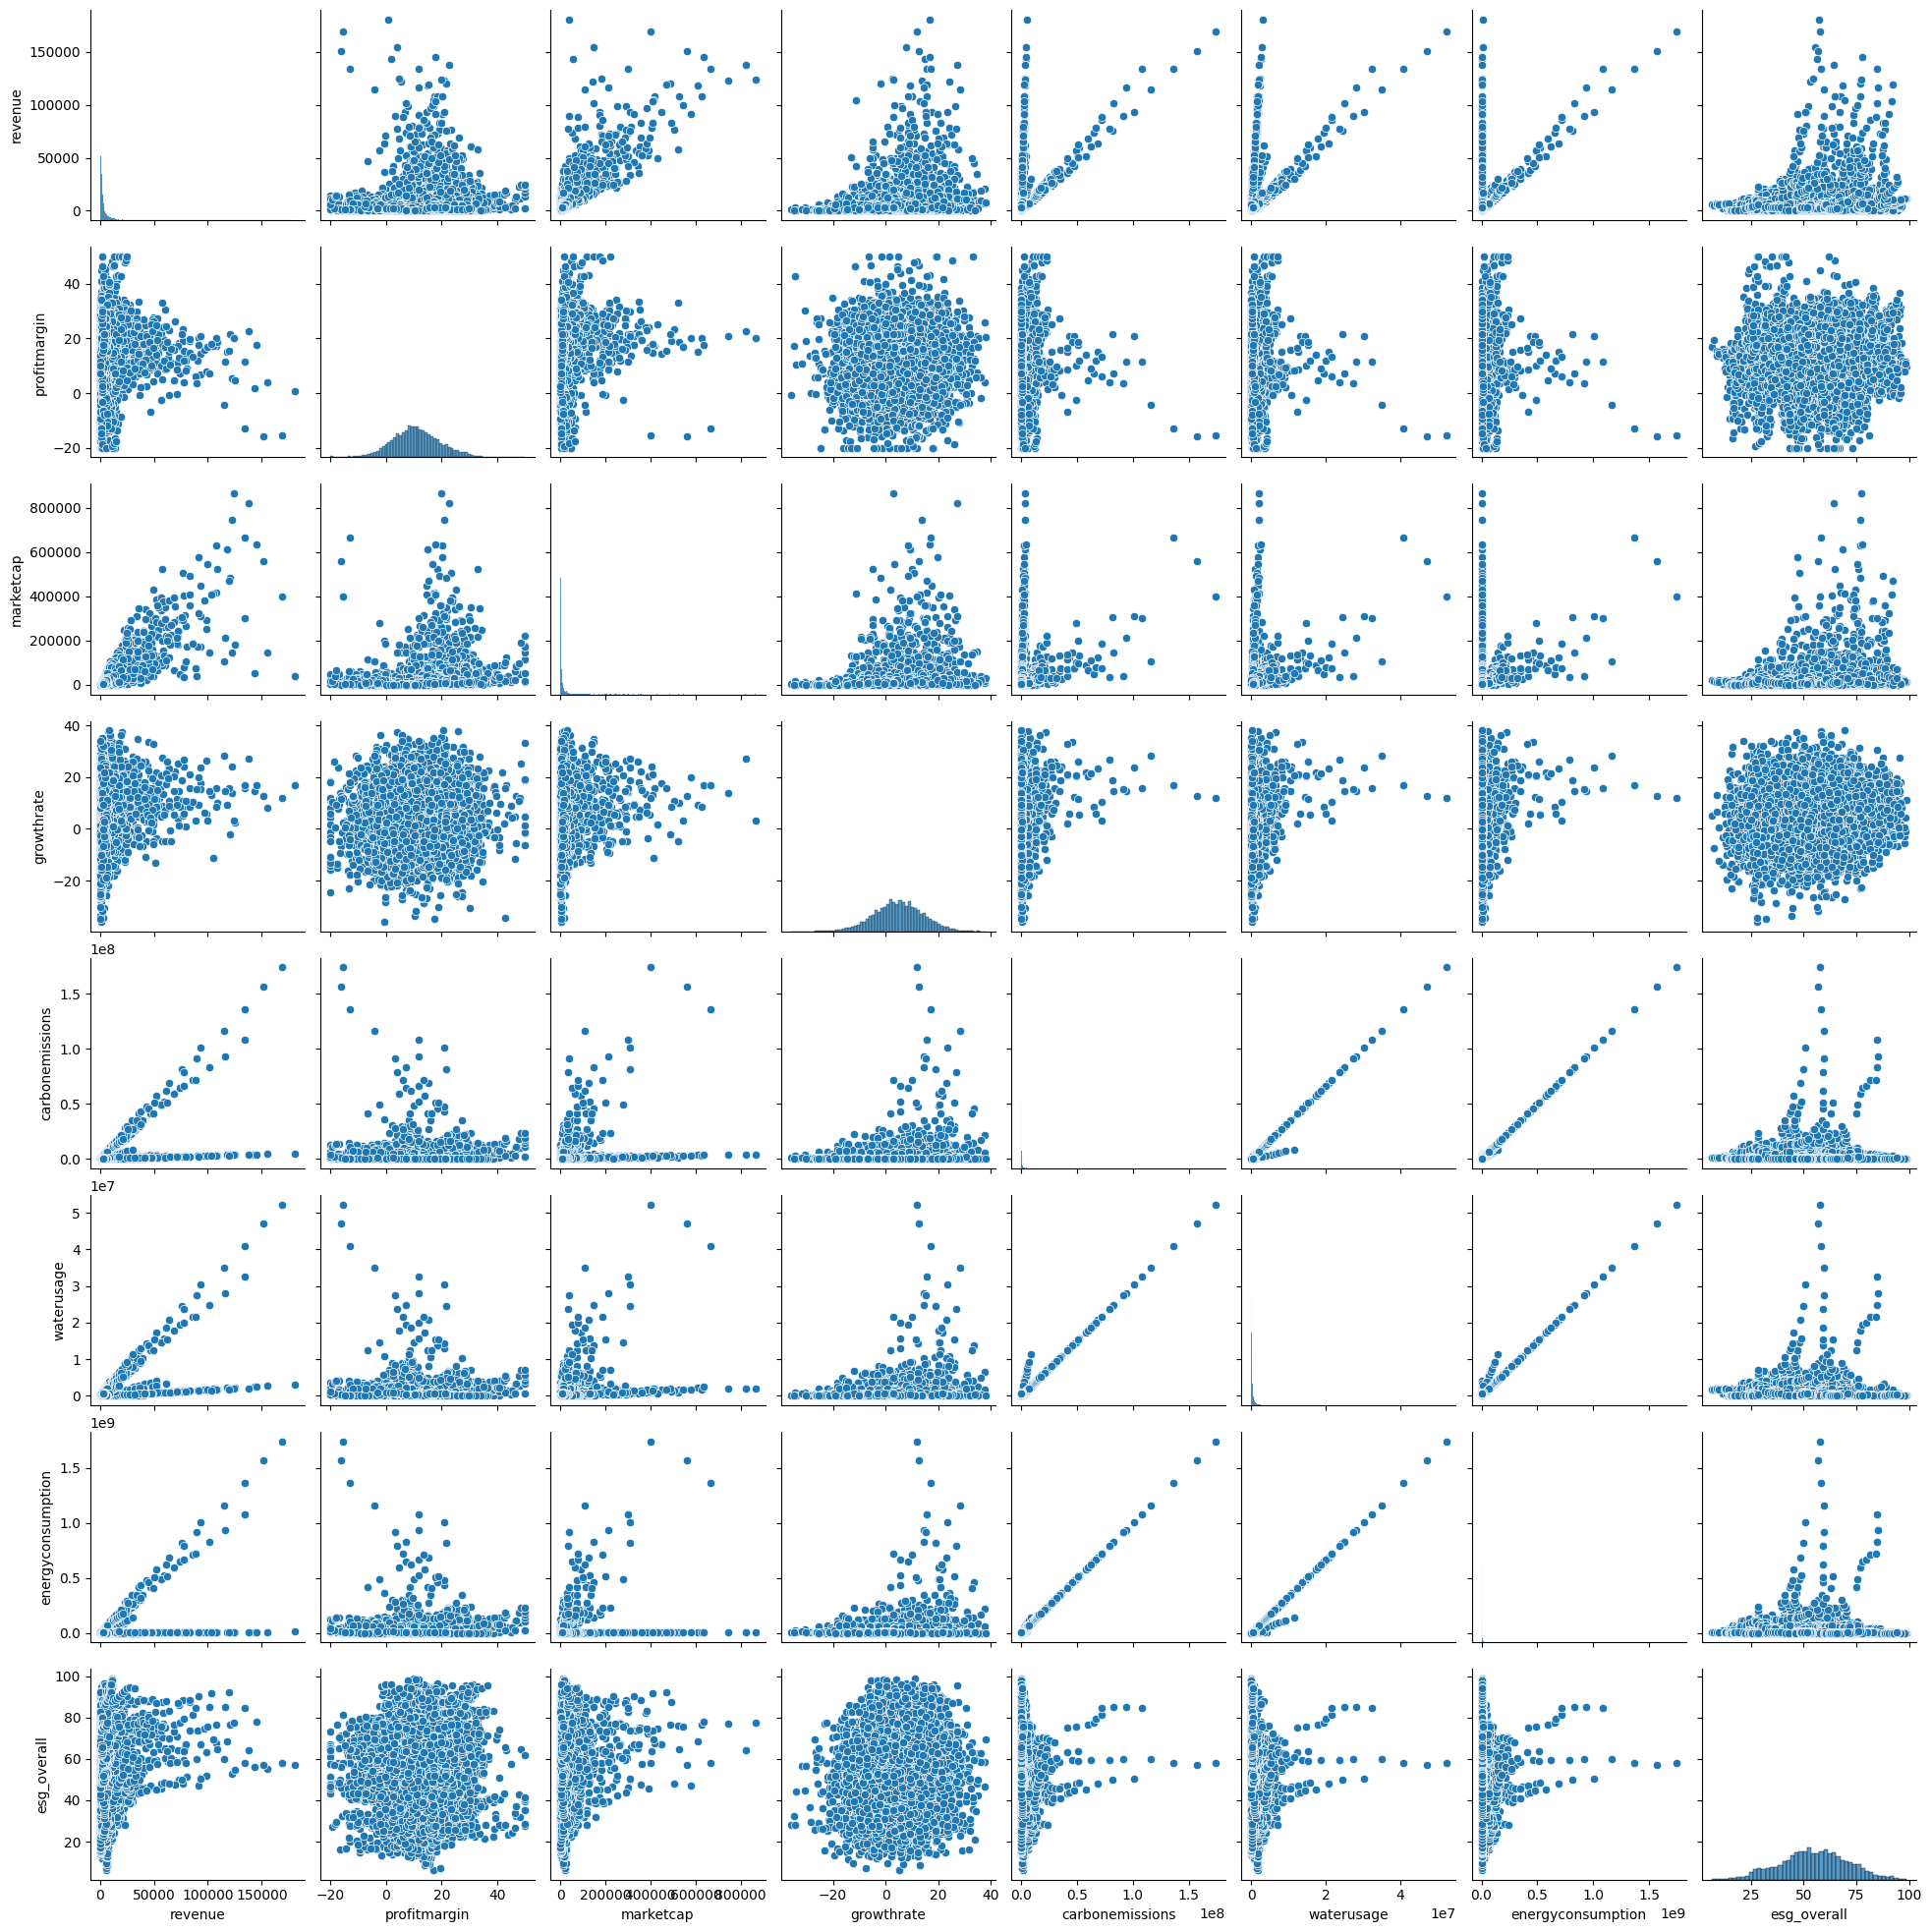

In [137]:
sns.pairplot(df_numeric[['revenue','profitmargin','marketcap','growthrate','carbonemissions','waterusage','energyconsumption','esg_overall']])

## **Feature Engineering**

Since we are using basline linear regression model and over that ensemble models, we need to create some feature to make the ML model valid.

In [138]:
#since these columns is heavily right skewed, we will create a new log transformed columns
df['log_revenue']=np.log1p(df['revenue'])
df['log_marketcap'] = np.log1p(df['marketcap'])
df['log_carbonemissions'] = np.log1p(df['carbonemissions'])
df['log_waterusage'] = np.log1p(df['waterusage'])
df['log_energyconsumption'] = np.log1p(df['energyconsumption'])

In [139]:
#among the variables, carbonemission, energyconsumption, waterusage are very importnt and relevant factors.
df['carbon_intensity']=df['carbonemissions']/df['revenue']*100
df['carbon_intensity']
#This is a very common sustainability metric. It sees which company, which region as more carbon efficient, rather than absolute carbon emissions
#we check relative carbon emission to its revenue

,carbon_intensity
1,7875.62
2,7967.14
3,7637.91
4,7538.21
5,7444.12
...,...
10995,14590.42
10996,14380.29
10997,13858.58
10998,13863.75


In [140]:
df['energyintensity']=df['energyconsumption']/df['revenue']*100
df['energyintensity'].head()

,energyintensity
1,15751.25
2,15934.31
3,15275.82
4,15076.43
5,14888.26


In [141]:
df['waterintensity']=df['waterusage']/df['revenue']*100
df['waterintensity'].head()

,waterintensity
1,3937.82
2,3983.57
3,3818.96
4,3769.11
5,3722.06


In [142]:
from google.colab import files

# Save the processed DataFrame to a new CSV file
df.to_csv('processed_company_esg_financial_dataset.csv', index=False)

# Download the newly created file
files.download('processed_company_esg_financial_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## **Data Preprocessing**

In [143]:
df.head()

,companyid,companyname,industry,region,year,revenue,profitmargin,marketcap,growthrate,esg_overall,...,waterusage,energyconsumption,log_revenue,log_marketcap,log_carbonemissions,log_waterusage,log_energyconsumption,carbon_intensity,energyintensity,waterintensity
1,1,company_1,retail,latin_america,2016,473.80,4.60,366.60,3.20,56.70,...,18657.40,74629.40,6.16,5.91,10.53,9.83,11.22,7875.62,15751.25,3937.82
2,1,company_1,retail,latin_america,2017,564.90,5.20,313.40,19.20,56.50,...,22503.20,90012.90,6.34,5.75,10.71,10.02,11.41,7967.14,15934.31,3983.57
3,1,company_1,retail,latin_america,2018,558.40,4.30,283.00,-1.10,58.00,...,21325.10,85300.20,6.33,5.65,10.66,9.97,11.35,7637.91,15275.82,3818.96
4,1,company_1,retail,latin_america,2019,554.50,4.90,538.10,-0.70,56.60,...,20899.70,83598.80,6.32,6.29,10.64,9.95,11.33,7538.21,15076.43,3769.11
5,1,company_1,retail,latin_america,2020,567.50,6.00,384.10,2.30,55.70,...,21122.70,84490.90,6.34,5.95,10.65,9.96,11.34,7444.12,14888.26,3722.06


In [144]:
df.columns

Index(['companyid', 'companyname', 'industry', 'region', 'year', 'revenue',
       'profitmargin', 'marketcap', 'growthrate', 'esg_overall',
       'esg_environmental', 'esg_social', 'esg_governance', 'carbonemissions',
       'waterusage', 'energyconsumption', 'log_revenue', 'log_marketcap',
       'log_carbonemissions', 'log_waterusage', 'log_energyconsumption',
       'carbon_intensity', 'energyintensity', 'waterintensity'],
      dtype='object')

In [145]:
X = df.drop(['esg_overall',
             'esg_environmental',
             'esg_social',
             'esg_governance',
             'revenue',
             'marketcap',
             'carbonemissions',
             'waterusage',
             'energyconsumption'], axis=1)

y = df['esg_overall']

In [146]:
from sklearn.model_selection import train_test_split

In [147]:
X_train, X_test, y_train, y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [148]:
print(len(X_train), len(y_train))

8000 8000


In [149]:
#import libraries
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [150]:
#define numeric and categprical variables.

numeric_features = ['profitmargin', 'growthrate', 'year',
                     'log_revenue', 'log_marketcap', 'log_carbonemissions',
                     'log_waterusage', 'log_energyconsumption',
                     'carbon_intensity', 'energyintensity', 'waterintensity']

categorical=['industry','region']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical),
        ('num', StandardScaler(), numeric_features)
    ]
)

In [151]:
#fit on the training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [152]:
#see what has changed in the dataset
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['cat__industry_consumer_goods' 'cat__industry_energy'
 'cat__industry_finance' 'cat__industry_healthcare'
 'cat__industry_manufacturing' 'cat__industry_retail'
 'cat__industry_technology' 'cat__industry_transportation'
 'cat__industry_utilities' 'cat__region_africa' 'cat__region_asia'
 'cat__region_europe' 'cat__region_latin_america'
 'cat__region_middle_east' 'cat__region_north_america'
 'cat__region_oceania' 'num__profitmargin' 'num__growthrate' 'num__year'
 'num__log_revenue' 'num__log_marketcap' 'num__log_carbonemissions'
 'num__log_waterusage' 'num__log_energyconsumption'
 'num__carbon_intensity' 'num__energyintensity' 'num__waterintensity']


## **Model Building**

#### **1.Baseline Model: Linear Regression**

Linear Regression has no hyperparameters to tune, so it does not need a validation set. A simple train/test split works perfectly.

In [173]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

linear_model.fit(X_train, y_train)

# quick sanity check on held-out test set
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

y_pred = linear_model.predict(X_test)
print("RMSE:", root_mean_squared_error(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("R²:", r2_score(y_test, y_pred))

RMSE: 9.584472913177896
MAE: 7.753015042403571
R²: 0.6516998174317026


Text(0, 0.5, 'Predicted ESG')

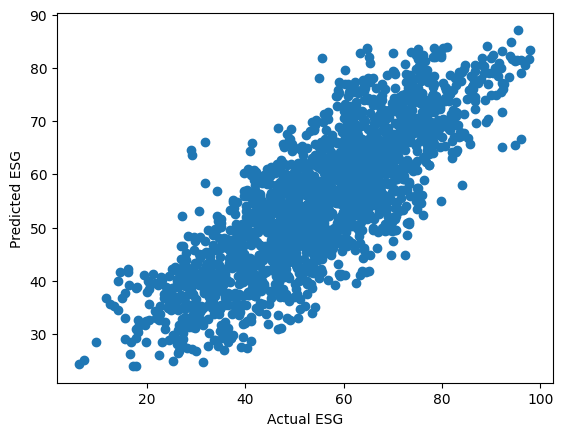

In [159]:
#check the accuracy of the model by visualizng it
plt.scatter(y_test, y_pred)
plt.xlabel("Actual ESG")
plt.ylabel("Predicted ESG")

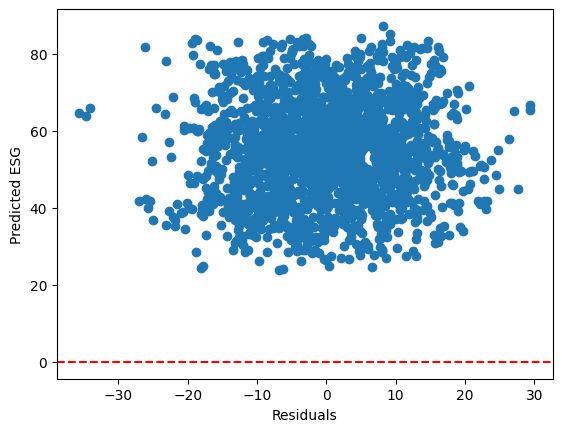

In [160]:
#plot the residuals
residuals = y_test - y_pred
plt.scatter(residuals, y_pred)
plt.xlabel("Residuals")
plt.ylabel("Predicted ESG")
plt.axhline(y=0, color='red', linestyle='--')
plt.show()

### **Cross Validation**

#### Can a more flexible model do better?

These are ensemble techniques, in such case cross validation is a good idea to make the model more accurate. Validation is mainly to avoide overfitting problems and nothing else. Overfitting means the model performs well on training data but fails in test data, to avoid that we have certain cross validation techniques. Mean the biasia increasing and the varience is reducing.   K-fold, stratified K-fold, leave-one-out, and others

##### **Cross validation: Group K fold classification**

Here's the key idea of K-Fold: across the 5 iterations, every row gets used as test data exactly once, and as training data in the other 4 folds. So instead of one fixed 80/20 split, you get 5 different 80/20-style splits (here it's actually 80/20 since 1 fold out of 5 = 20% test each time), and every single data point contributes to a test score exactly once.


In [163]:
from sklearn.model_selection import GroupKFold, cross_val_score
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor

In [164]:
# define the criteria
groups = df["companyid"]

gkf = GroupKFold(n_splits=5)

for train_idx, val_idx in gkf.split(X, y, groups):

    X_train_gkf = X.iloc[train_idx]
    X_val_gkf = X.iloc[val_idx]

    y_train_gkf = y.iloc[train_idx]
    y_val_gkf = y.iloc[val_idx]

print(
    "Train companies:",
    df.iloc[train_idx]["companyid"].nunique()
)

print(
    "Validation companies:",
    df.iloc[val_idx]["companyid"].nunique()
)

Train companies: 800
Validation companies: 200


In [165]:
# ---- Models to compare ----
regressors = {
    "Linear Regression": LinearRegression(),
    "XGBoost": XGBRegressor(random_state=42, verbosity=0),
    "Random Forest": RandomForestRegressor(random_state=42),
}

# ---- Run CV for each model ----
results = []

for name, regressor in regressors.items():
    model = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', regressor)
    ])

    rmse_scores = -cross_val_score(model, X, y, cv=gkf, scoring='neg_root_mean_squared_error', n_jobs=-1, groups=groups)
    mae_scores  = -cross_val_score(model, X, y, cv=gkf, scoring='neg_mean_absolute_error', n_jobs=-1, groups=groups)
    r2_scores   =  cross_val_score(model, X, y, cv=gkf, scoring='r2', n_jobs=-1, groups=groups)

    results.append({
        "Model": name,
        "RMSE_mean": rmse_scores.mean(),
        "RMSE_std": rmse_scores.std(),
        "MAE_mean": mae_scores.mean(),
        "MAE_std": mae_scores.std(),
        "R2_mean": r2_scores.mean(),
        "R2_std": r2_scores.std(),
    })

# ---- Results table ----
results_df = pd.DataFrame(results).sort_values("RMSE_mean")
print(results_df.round(4))

               Model  RMSE_mean  RMSE_std  MAE_mean  MAE_std  R2_mean  R2_std
0  Linear Regression       9.82      0.26      7.98     0.21     0.61    0.03
2  Gradient Boosting      10.43      0.32      8.44     0.23     0.57    0.03
4           CatBoost      10.81      0.13      8.75     0.19     0.53    0.03
1            XGBoost      11.46      0.19      9.25     0.21     0.47    0.04
3      Random Forest      11.71      0.30      9.40     0.22     0.45    0.06


## **Hyper Parameter Tuning**

Hyperparameter tuning was performed on all ensemble models using grouped cross-validation; tuned performance did not surpass the Linear Regression baseline, reinforcing that the relationship is predominantly linear rather than a product of under-optimized ensemble models.

In [166]:
#we define different paramter options
param_rf = {
    "regressor__n_estimators": [100, 200, 300, 500],
    "regressor__max_depth": [None, 10, 20, 30],
    "regressor__min_samples_split": [2, 5, 10],
    "regressor__min_samples_leaf": [1, 2, 4],
    "regressor__max_features": ["sqrt", "log2"]
}


In [167]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42))
])

In [170]:
#we tune them for random forest and fit it on our training data
from sklearn.model_selection import RandomizedSearchCV
rf_tuned = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_rf,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=gkf,
    verbose=2,
    random_state=42,
    n_jobs=-1
)


group_train=groups.iloc[train_idx]

rf_tuned.fit(X_train, y_train,groups=group_train)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


KeyboardInterrupt: 

In [ ]:
rf_tuned.best_params_

In [ ]:
best_rf = rf_tuned.best_estimator_ #for best combination of the parameters, that is the best model

In [ ]:
param_xgb = {
    "regressor__n_estimators": [100, 200, 300, 500],
    "regressor__learning_rate": [0.01, 0.05, 0.1],
    "regressor__max_depth": [3, 5, 7, 10],
    "regressor__subsample": [0.7, 0.8, 1.0],
    "regressor__colsample_bytree": [0.7, 0.8, 1.0],
}

In [ ]:
xgb_pipeline = Pipeline([
    ('preprocessor',preprocessor),
    ('regressor',XGBRegressor(random_state=42))
])

In [ ]:
xgb_tuned = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_xgb,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=gkf,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

group_train=groups.iloc[train_idx]
xgb_tuned.fit(X_train, y_train)

In [ ]:
xgb_tuned.best_params_

In [ ]:
best_xgb = xgb_tuned.best_estimator_


### **Comparing the models**

In [181]:
#for ease, create a dataset for the reults of both the models, it is easier to compare
results = []

models = {
    "Random Forest (Tuned)": best_rf,
    "XGBoost (Tuned)": best_xgb,
    "Linear Regression": linear_model
}

for name, model in models.items():

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "RMSE": root_mean_squared_error(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R²": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)

results_df.round(3)

,Model,RMSE,MAE,R²
0,Random Forest (Tuned),16.30,13.13,-0.01
1,XGBoost (Tuned),16.25,13.11,-0.00
2,Linear Regression,9.58,7.75,0.65


In [174]:
best_model=linear_model

## **Feature Importance**

In [175]:
import pandas as pd

feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
coefficients = best_model.named_steps['regressor'].coef_

importances = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

importances['Abs_Coefficient'] = importances['Coefficient'].abs()
importances = importances.sort_values('Abs_Coefficient', ascending=False)

print(importances.head(15))

                         Feature  Coefficient  Abs_Coefficient
21      num__log_carbonemissions    259880.22        259880.22
23    num__log_energyconsumption   -207886.40        207886.40
4    cat__industry_manufacturing    195750.79        195750.79
7   cat__industry_transportation   -114158.65        114158.65
22           num__log_waterusage   -104732.15        104732.15
5           cat__industry_retail    -90707.75         90707.75
8        cat__industry_utilities     90648.96         90648.96
6       cat__industry_technology    -78096.89         78096.89
2          cat__industry_finance    -67775.55         67775.55
0   cat__industry_consumer_goods     67227.59         67227.59
3       cat__industry_healthcare    -42667.04         42667.04
1           cat__industry_energy     39778.55         39778.55
19              num__log_revenue        38.09            38.09
11            cat__region_europe        12.57            12.57
13       cat__region_middle_east       -11.56          

In [ ]:
best_model=linear_model

In [ ]:
import joblib

# Save the model
joblib.dump(best_model, "best_model.pkl")

print("Model saved successfully!")

/tmp/ipykernel_3227/118921613.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_features, x='Coefficient', y='Feature',


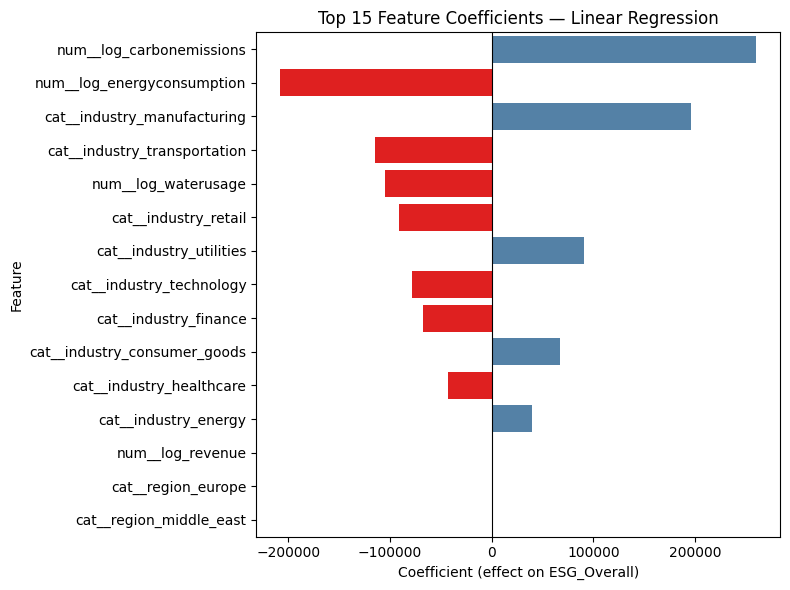

In [176]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
top_features = importances.head(15)
sns.barplot(data=top_features, x='Coefficient', y='Feature',
            palette=['red' if c < 0 else 'steelblue' for c in top_features['Coefficient']])
plt.axvline(x=0, color='black', linewidth=0.8)
plt.title('Top 15 Feature Coefficients — Linear Regression')
plt.xlabel('Coefficient (effect on ESG_Overall)')
plt.tight_layout()
plt.show()